In [1]:
# args.seed, args.in_folder, args.out_folder, 
# args.color_mode:  'gray' or 'rgb', args.sigma_min, args.sigma_max, args.patch_size, 
# args.epochs, args.batch_size, args.lr, args.sch: 'multistep' or 'cosine', args.lr_step, args.lr_gamma, 
# args.val_freq, args.save_freq, args.progress_freq, args.save_img_freq,
# args.blind, args.patch_rad, args.window_rad, args.in_channel, args.latent_dim, args.latent_channel_dim
class config:
    def __init__(self):
        pass

args = config()

args.seed = 100
args.in_folder = './data'
args.out_folder = './output'
args.color_mode = 'rgb'
args.sigma_min = 20
args.sigma_max = 20
args.patch_size = 128
args.epochs = 5
args.batch_size = 20
args.lr = 1e-3
args.sch = 'cosine'
args.lr_step = None
args.lr_gamma = None
args.val_freq = 1
args.save_freq = 1
args.save_img = True
args.save_img_freq = 1
args.progress_freq = 1
args.patch_rad = 1
args.window_rad = 1
args.in_channel = 3
args.latent_dim = 64
args.latent_channel_dim = 1
args.blind = True
verbose = True


info = train(args, verbose)

In [2]:
# import torch
# import numpy as np
# from dataset_loaders import create_dataloaders, TestDataset
# import torch.nn as nn
# import torch.optim as optim
# import os
# from NKD_linear_layer import NKD_latent_layers, save_checkpoint
# from torch.utils.data import Dataset, DataLoader
# from test import Test_denoisers

In [3]:

# torch.manual_seed(args.seed)
# np.random.seed(args.seed)

# # Setup device
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# if verbose:
#     print(f"Using device: {device}")

# # Create training dataset and dataloader
# train_loader, val_loader = create_dataloaders(args)

# testset = TestDataset('./data/show', 'rgb', 15, show=True)

# test_loader = DataLoader(
#             testset,
#             batch_size=1,  # Process one full image at a time
#             shuffle=False,
#             pin_memory=True
#         )

# # Create model
# in_nc = out_nc = 1 if args.color_mode == 'gray' else 3
# model = NKD_latent_layers(
#     patch_rad=args.patch_rad,
#     window_rad=args.window_rad,
#     in_channel=args.in_channel,
#     latent_dim=args.latent_dim,
#     latent_channel_dim=args.latent_channel_dim,
#     device=device, 
#     blind = args.blind
# ).to(device)

# _state = f'_{args.patch_rad}{args.window_rad}{args.in_channel}{args.latent_dim}{args.latent_channel_dim}{int(args.blind)}{args.sigma_min}_{args.sigma_max}'
# args.out_folder = args.out_folder+_state
# # Check if the output folder exists
# if not os.path.exists(args.out_folder):
#     # Create the folder
#     os.makedirs(args.out_folder)
#     if verbose:
#         print(f"Folder created at: {args.out_folder}")

# # Setup optimizer, scheduler and criterion
# optimizer = optim.AdamW(model.parameters(), lr=args.lr)
# if args.sch == 'multistep':
#     if isinstance(args.lr_step, str):
#         milestones = [int(x) for x in args.lr_step.split(',')]
#     else:
#         milestones = [args.lr_step]
#     # Multi-step learning rate scheduler
#     scheduler = optim.lr_scheduler.MultiStepLR(
#         optimizer, milestones=milestones, gamma=args.lr_gamma
#     )
# elif args.sch == 'cosine':
#     # Cosine annealing learning rate scheduler
#     scheduler = optim.lr_scheduler.CosineAnnealingLR(
#         optimizer, T_max=args.epochs
#     )
# else:
#     raise ValueError(f"scehduler(={args.sch}) is not defined")

# criterion = nn.MSELoss()
# # For tracking best validation results
# best_psnr = 0
# best_ssim = 0

# # Training loop
# total_steps = 0
# model.train()

# start_time = torch.cuda.Event(enable_timing=True)
# end_time = torch.cuda.Event(enable_timing=True)
# start_time.record()
# losses = []
# val_metric = []
# # try:
# for epoch in range(args.epochs):
#     batch_count = 0

#     loss = model.train_step(train_loader, criterion, optimizer)
#     total_steps += 1
#     batch_count += 1
#     losses.append(loss)

#     # Validation
#     if val_loader is not None and total_steps % args.val_freq == 0:
#         model.eval()
#         with torch.autocast(device_type="cuda", dtype=torch.float32):
#             mertics = model.val_step(val_loader)
#             avg_psnr, avg_ssim = mertics['psnr'], mertics['ssim']
#         model.train()
#         val_metric.append((avg_psnr, avg_ssim))
#         if verbose:
#             print(f"\nStep {total_steps} Validation:")
#             print(f"PSNR: {avg_psnr:.2f}dB, SSIM: {avg_ssim:.4f}")

#         # Track best results
#         is_best = False
#         if avg_psnr > best_psnr:
#             best_psnr = avg_psnr
#             is_best = True
#             if verbose:
#                 print(f"New best PSNR: {best_psnr:.2f}dB")
#         if avg_ssim > best_ssim:
#             best_ssim = avg_ssim
#             is_best = True
#             if verbose:
#                 print(f"New best SSIM: {best_ssim:.4f}")

#         # Save checkpoint
#         if is_best:
#             save_checkpoint(args.out_folder, {
#                 'step': total_steps,
#                 'epoch': epoch,
#                 'model_state_dict': model.state_dict(),
#                 'loss': loss,
#                 'psnr': avg_psnr,
#                 'ssim': avg_ssim,
#                 'best_psnr': best_psnr,
#                 'best_ssim': best_ssim,
#                 'args': args,
#             }, total_steps, True)

#         # Log metrics
#         with open(os.path.join(args.out_folder, 'validation_log.txt'), 'a') as f:
#             f.write(f'{total_steps},{
#                     avg_psnr:.4f},{avg_ssim:.4f}\n')

#     # Regular checkpoint saving
#     if total_steps % args.save_freq == 0:
#         print('saving checkpoint')
#         save_checkpoint(args.out_folder, {
#             'step': total_steps,
#             'epoch': epoch,
#             'model_state_dict': model.state_dict(),
#             'loss': loss,
#             'args': args,
#         }, total_steps)

#     # Print progress
#     if total_steps % args.progress_freq == 0:
#         print(f"Epoch {epoch+1}/{args.epochs} | Batch {batch_count}/{len(train_loader)} | "
#                 f"Loss: {loss:.6f}", end='\r')

#     scheduler.step()

#     if args.save_img and total_steps % args.save_img_freq == 0:
#         with torch.autocast(device_type="cuda", dtype=torch.float32):
#             Test_denoisers(test_loader, [model], ['NKD'], device)

#     # Print epoch statistics
#     avg_loss = loss / batch_count
    
#     # Save epoch loss to log
#     with open(os.path.join(args.out_folder, 'training_log.txt'), 'a') as f:
#         f.write(f'{epoch+1},{avg_loss:.6f}\n')

# end_time.record()
# torch.cuda.synchronize()
# training_time = start_time.elapsed_time(
#     end_time) / 1000  # Convert to seconds

# print("\nTraining complete!")
# print(f"Total training time: {training_time/3600:.2f} hours")
# print(f"Best PSNR: {best_psnr:.2f}dB")
# print(f"Best SSIM: {best_ssim:.4f}")

# # Save final metrics
# with open(os.path.join(args.out_folder, 'final_metrics.txt'), 'w') as f:
#     f.write(f"Training Time (hours): {training_time/3600:.2f}\n")
#     f.write(f"Best PSNR (dB): {best_psnr:.2f}\n")
#     f.write(f"Best SSIM: {best_ssim:.4f}\n")
#     f.write(f"Final Loss: {
#             loss/batch_count if batch_count > 0 else float('inf'):.6f}\n")

# # Clean up
# if torch.cuda.is_available():
#     torch.cuda.empty_cache()


Using device: cuda

Loading training images...
Loaded 400 images from BSD400
Total loaded 400 images from: BSD400
Loaded 400 images for training
Total loaded 32 images from: ./data/val/BSD32
Loaded 32 images for validation

Loading testing images...
Loaded 2 images from curr_test
Total loaded 2 images from: curr_test
Loaded 2 images for testing

Step 1 Validation:
PSNR: 29.34dB, SSIM: 0.8362
New best PSNR: 29.34dB
New best SSIM: 0.8362
saving checkpoint
./output_113641120_20/output_images__113641120_20_1.png

Step 2 Validation:
PSNR: 29.51dB, SSIM: 0.8390
New best PSNR: 29.51dB
New best SSIM: 0.8390
saving checkpoint
./output_113641120_20/output_images__113641120_20_2.png

Step 3 Validation:
PSNR: 29.62dB, SSIM: 0.8407
New best PSNR: 29.62dB
New best SSIM: 0.8407
saving checkpoint
./output_113641120_20/output_images__113641120_20_3.png

Step 4 Validation:
PSNR: 29.67dB, SSIM: 0.8415
New best PSNR: 29.67dB
New best SSIM: 0.8415
saving checkpoint
./output_113641120_20/output_images__1136

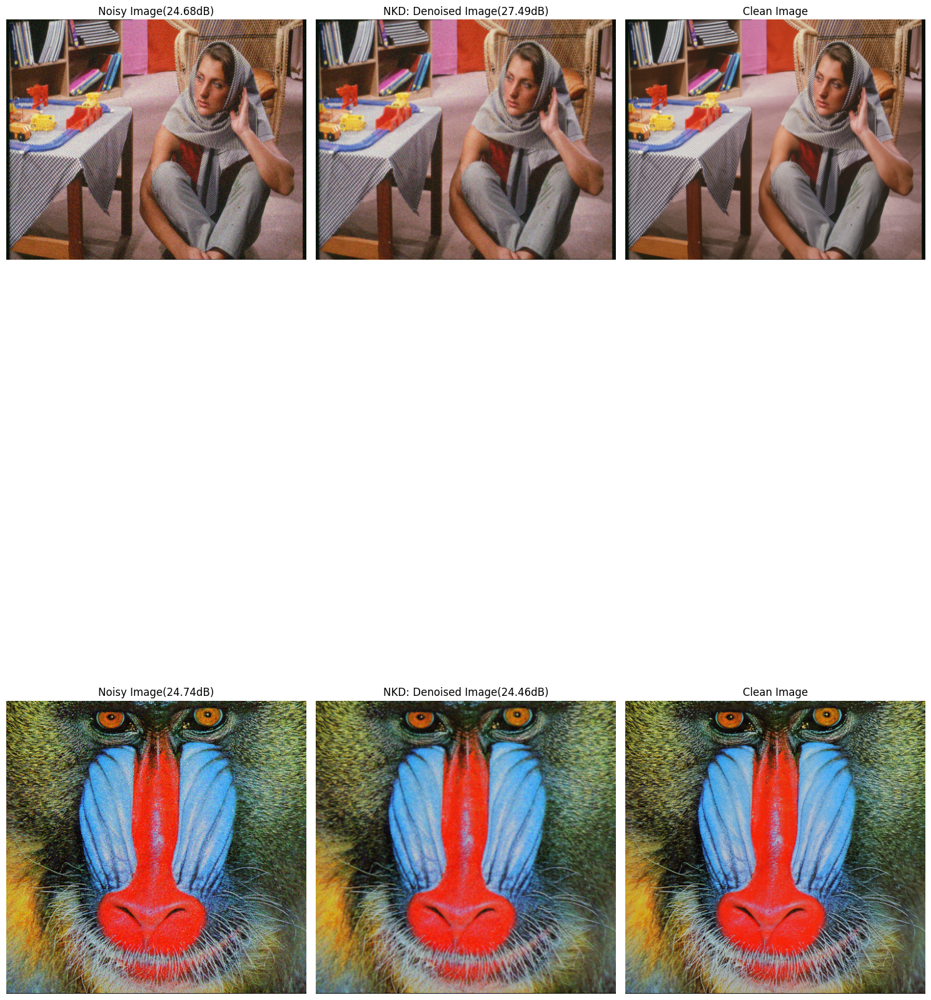

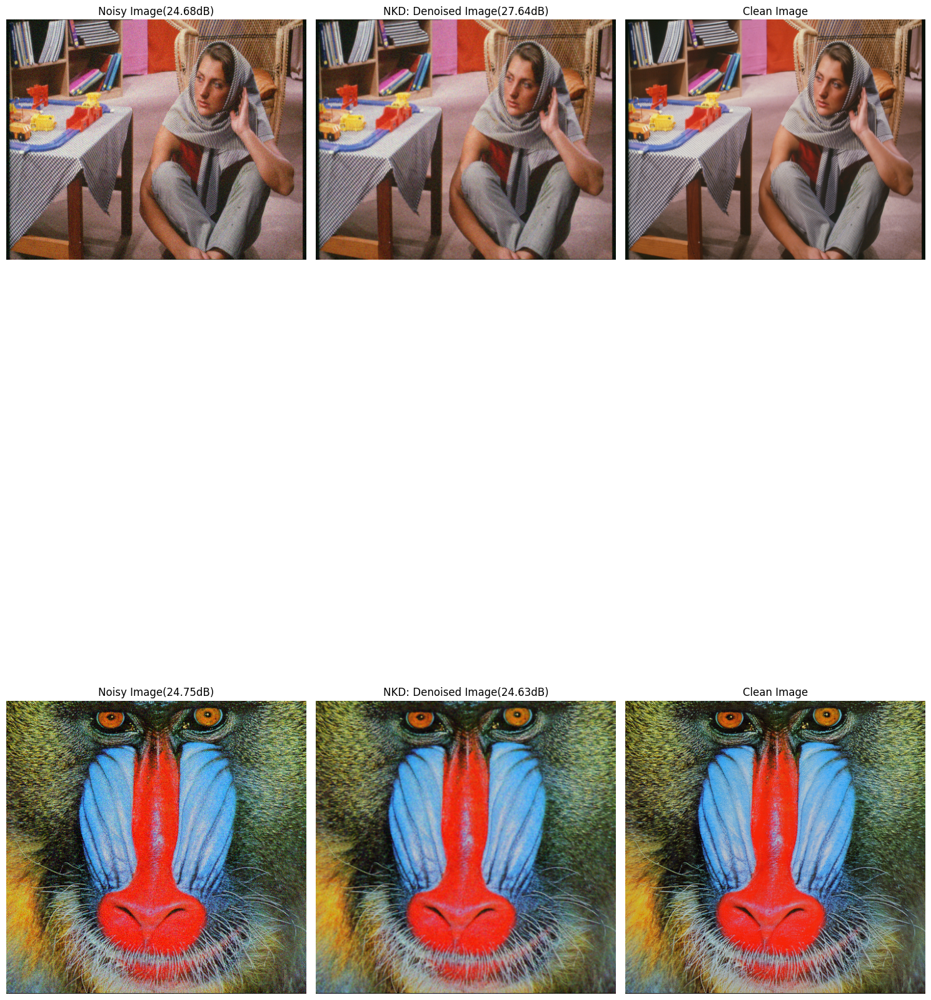

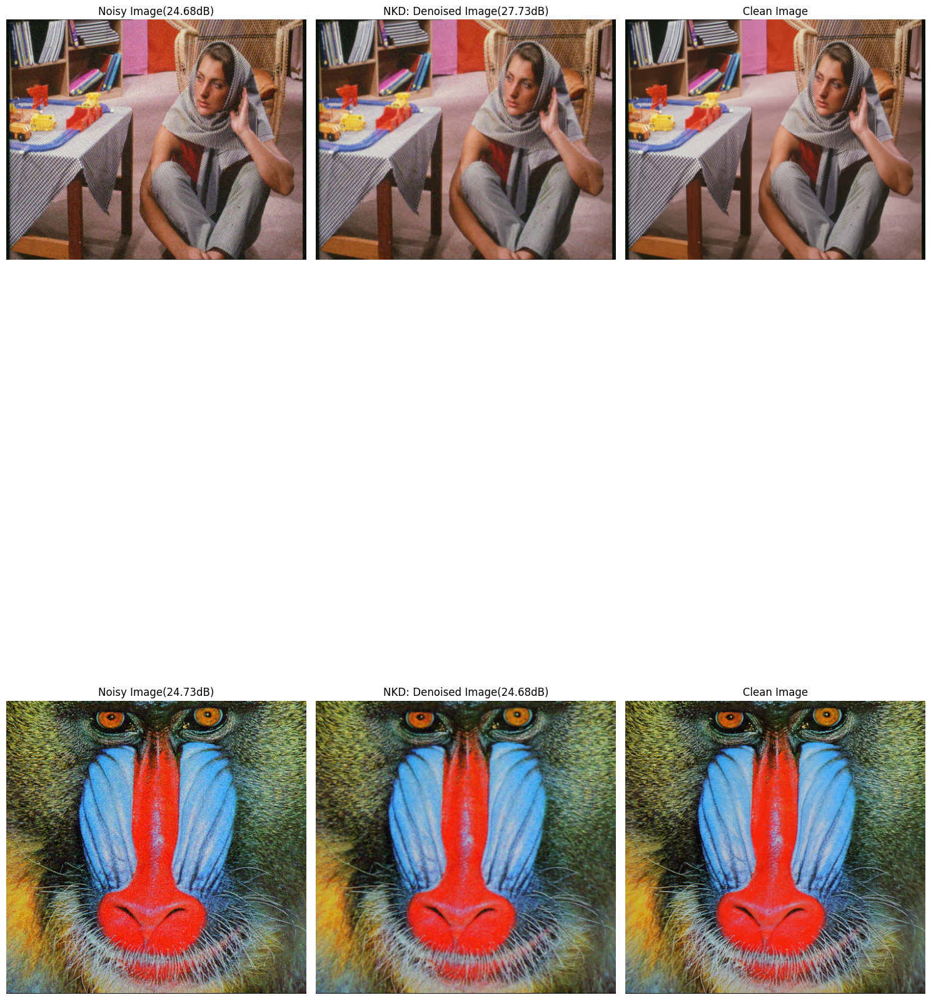

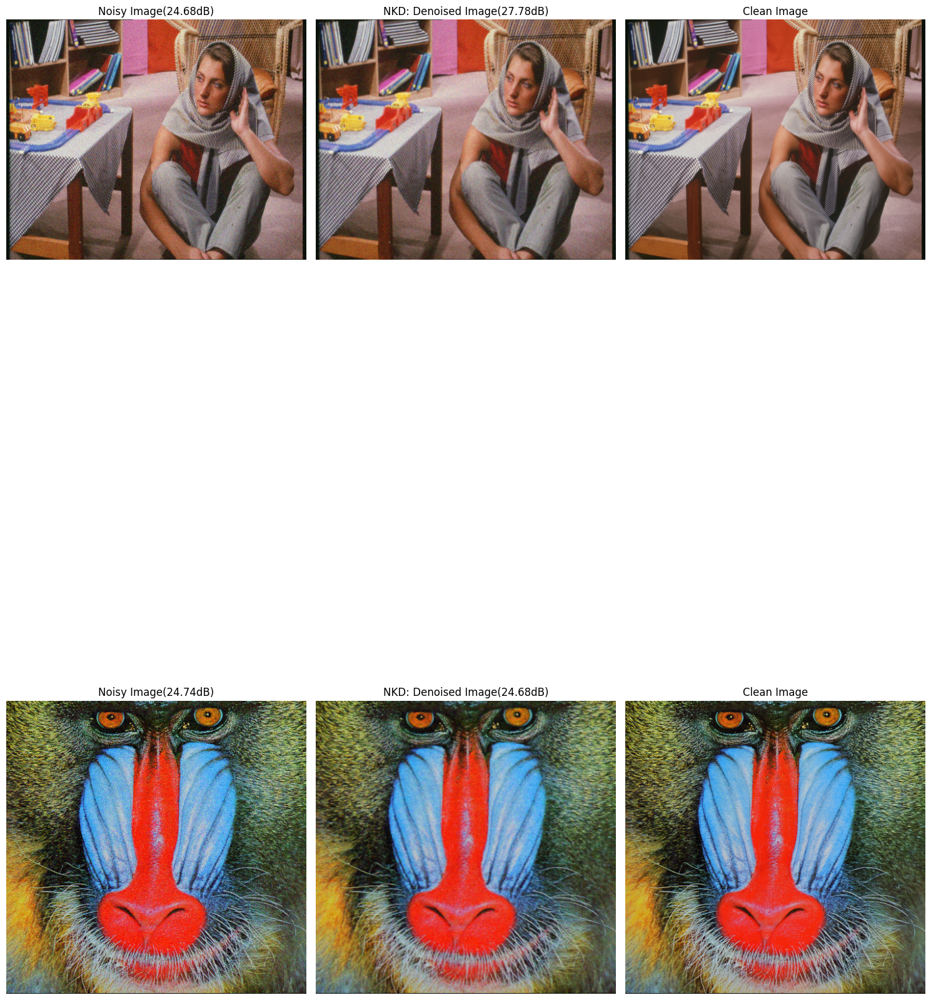

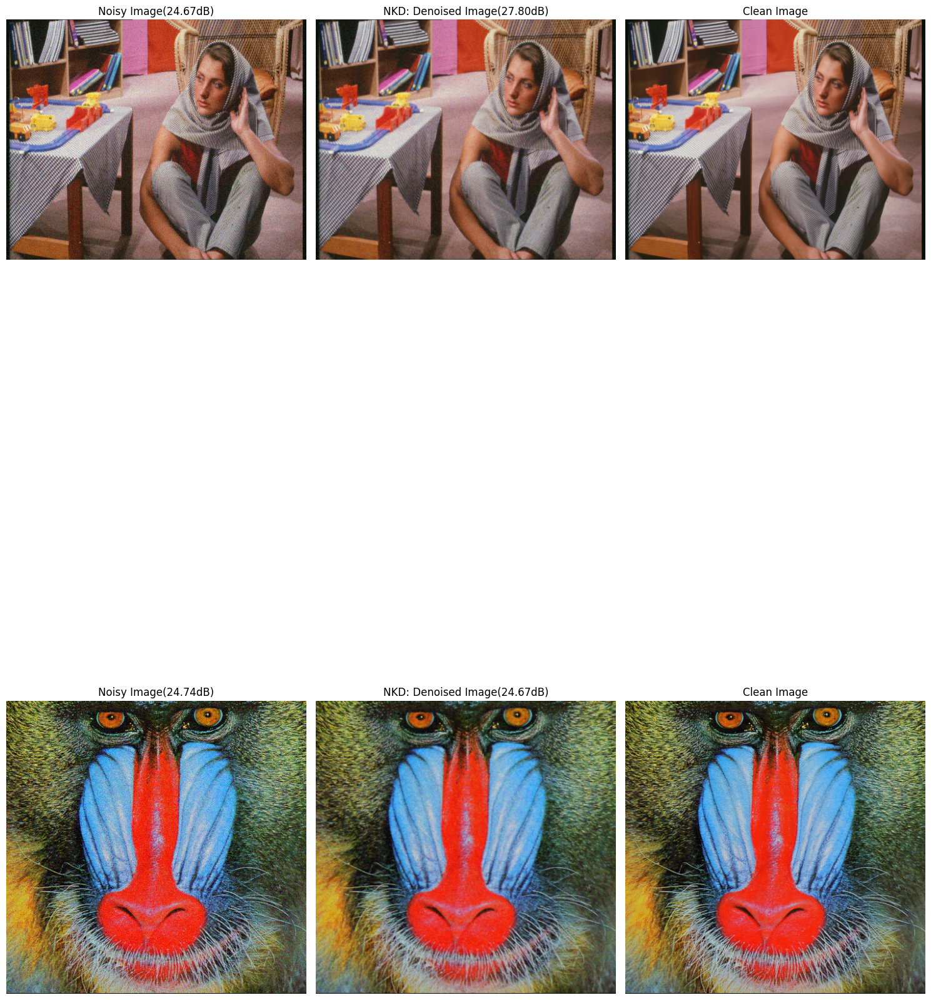

In [3]:
from NKD_train import train
#10
train(config, False)


Loading training images...
Loaded 400 images from BSD400
Loaded 900 images from DIV2K
Loaded 2650 images from Flickr2K
Skipping 04118.bmp: Invalid RGB shape (440, 660, 4)
Skipping 01728.bmp: Invalid RGB shape (319, 480, 4)
Skipping 02758.bmp: Invalid RGB shape (500, 676, 4)
Skipping 02749.bmp: Invalid RGB shape (300, 400, 4)
Skipping 02766.bmp: Invalid RGB shape (500, 676, 4)
Skipping 03665.bmp: Invalid RGB shape (408, 600, 4)
Skipping 02763.bmp: Invalid RGB shape (500, 676, 4)
Skipping 00027.bmp: Invalid RGB shape (500, 676, 4)
Skipping 03251.bmp: Invalid RGB shape (491, 500, 4)
Loaded 4735 images from waterloo_exploration
Total loaded 8685 images from: BSD400, DIV2K, Flickr2K, waterloo_exploration
Loaded 8685 images for training
Total loaded 32 images from: ./data/val/BSD32
Loaded 32 images for validation

Epoch 1/50000 | Avg Loss: 0.007075

Epoch 2/50000 | Avg Loss: 0.006187

Epoch 3/50000 | Avg Loss: 0.005332

Epoch 4/50000 | Avg Loss: 0.005161

Epoch 5/50000 | Avg Loss: 0.005552


In [2]:
from NKD_train import train
#10
train(config, True)

Using device: cuda

Loading training images...
Loaded 400 images from BSD400
Total loaded 400 images from: BSD400
Loaded 400 images for training
Total loaded 32 images from: ./data/val/BSD32
Loaded 32 images for validation

Epoch 1/100 | Avg Loss: 0.007596

Epoch 2/100 | Avg Loss: 0.007028

Epoch 3/100 | Avg Loss: 0.005046

Epoch 4/100 | Avg Loss: 0.005940

Epoch 5/100 | Avg Loss: 0.007278

Epoch 6/100 | Avg Loss: 0.005511

Epoch 7/100 | Avg Loss: 0.008658

Epoch 8/100 | Avg Loss: 0.005807

Epoch 9/100 | Avg Loss: 0.007747

Epoch 10/100 | Avg Loss: 0.004584

Epoch 11/100 | Avg Loss: 0.006299

Epoch 12/100 | Avg Loss: 0.005219

Epoch 13/100 | Avg Loss: 0.007411

Epoch 14/100 | Avg Loss: 0.007204

Epoch 15/100 | Avg Loss: 0.006540

Epoch 16/100 | Avg Loss: 0.004220

Epoch 17/100 | Avg Loss: 0.007689

Epoch 18/100 | Avg Loss: 0.006496

Epoch 19/100 | Avg Loss: 0.006722

Epoch 20/100 | Avg Loss: 0.005892

Epoch 21/100 | Avg Loss: 0.007666

Epoch 22/100 | Avg Loss: 0.005971

Epoch 23/100 | 

In [2]:
from NKD_train import train
#10
train(config, True)

Using device: cuda

Loading training images...
Loaded 400 images from BSD400
Total loaded 400 images from: BSD400
Loaded 400 images for training
Total loaded 32 images from: ./data/val/BSD32
Loaded 32 images for validation

Epoch 1/100 | Avg Loss: 0.003070

Epoch 2/100 | Avg Loss: 0.001059

Epoch 3/100 | Avg Loss: 0.000656

Epoch 4/100 | Avg Loss: 0.000620

Epoch 5/100 | Avg Loss: 0.000706

Epoch 6/100 | Avg Loss: 0.000435

Epoch 7/100 | Avg Loss: 0.000613

Epoch 8/100 | Avg Loss: 0.000477

Epoch 9/100 | Avg Loss: 0.000499

Epoch 10/100 | Avg Loss: 0.000394

Epoch 11/100 | Avg Loss: 0.000515

Epoch 12/100 | Avg Loss: 0.000426

Epoch 13/100 | Avg Loss: 0.000493

Epoch 14/100 | Avg Loss: 0.000462

Epoch 15/100 | Avg Loss: 0.000414

Epoch 16/100 | Avg Loss: 0.000398

Epoch 17/100 | Avg Loss: 0.000476

Epoch 18/100 | Avg Loss: 0.000418

Epoch 19/100 | Avg Loss: 0.000458

Epoch 20/100 | Avg Loss: 0.000422

Epoch 21/100 | Avg Loss: 0.000457

Epoch 22/100 | Avg Loss: 0.000434

Epoch 23/100 | 

In [2]:
from NKD_train import train
#20
train(config, True)

Using device: cuda

Loading training images...
Loaded 400 images from BSD400
Total loaded 400 images from: BSD400
Loaded 400 images for training
Total loaded 32 images from: ./data/val/BSD32
Loaded 32 images for validation

Epoch 1/100 | Avg Loss: 0.001848

Epoch 2/100 | Avg Loss: 0.000834

Epoch 3/100 | Avg Loss: 0.000535

Epoch 4/100 | Avg Loss: 0.000548

Epoch 5/100 | Avg Loss: 0.000618

Epoch 6/100 | Avg Loss: 0.000421

Epoch 7/100 | Avg Loss: 0.000556

Epoch 8/100 | Avg Loss: 0.000461

Epoch 9/100 | Avg Loss: 0.000481

Epoch 10/100 | Avg Loss: 0.000373

Epoch 11/100 | Avg Loss: 0.000480

Epoch 12/100 | Avg Loss: 0.000404

Epoch 13/100 | Avg Loss: 0.000473

Epoch 14/100 | Avg Loss: 0.000442

Epoch 15/100 | Avg Loss: 0.000397

Epoch 16/100 | Avg Loss: 0.000384

Epoch 17/100 | Avg Loss: 0.000459

Epoch 18/100 | Avg Loss: 0.000406

Epoch 19/100 | Avg Loss: 0.000441

Epoch 20/100 | Avg Loss: 0.000406

Epoch 21/100 | Avg Loss: 0.000441

Epoch 22/100 | Avg Loss: 0.000420

Epoch 23/100 | 

In [2]:
from NKD_train import train

train(config, True)

Using device: cuda

Loading training images...
Loaded 400 images from BSD400
Total loaded 400 images from: BSD400
Loaded 400 images for training
Total loaded 32 images from: ./data/val/BSD32
Loaded 32 images for validation

Epoch 1/100 | Avg Loss: 0.001276

Epoch 2/100 | Avg Loss: 0.000737

Epoch 3/100 | Avg Loss: 0.000480

Epoch 4/100 | Avg Loss: 0.000520

Epoch 5/100 | Avg Loss: 0.000584

Epoch 6/100 | Avg Loss: 0.000415

Epoch 7/100 | Avg Loss: 0.000534

Epoch 8/100 | Avg Loss: 0.000439

Epoch 9/100 | Avg Loss: 0.000464

Epoch 10/100 | Avg Loss: 0.000361

Epoch 11/100 | Avg Loss: 0.000456

Epoch 12/100 | Avg Loss: 0.000385

Epoch 13/100 | Avg Loss: 0.000456

Epoch 14/100 | Avg Loss: 0.000424

Epoch 15/100 | Avg Loss: 0.000376

Epoch 16/100 | Avg Loss: 0.000368

Epoch 17/100 | Avg Loss: 0.000443

Epoch 18/100 | Avg Loss: 0.000394

Epoch 19/100 | Avg Loss: 0.000423

Epoch 20/100 | Avg Loss: 0.000393

Epoch 21/100 | Avg Loss: 0.000430

Epoch 22/100 | Avg Loss: 0.000408

Epoch 23/100 | 